# RRF 하이브리드 검색

**이 노트북에서 할 일**

1. 05절과 같은 두 검색 방법의 순위 목록을 다시 만듭니다.
2. 자리 번호만 써서 두 순위를 하나로 합치는 함수를 만듭니다.
3. 가중치 하나만 올려 합친 순위가 어떻게 달라지는지 봅니다.
4. 질문 여덟 개에서 세 방법의 정답 자리와 재현율을 견줍니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 1번과 질문 8번으로 모두 아홉 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.
실행 시간은 1분 안팎이고 첫 셀의 설치가 가장 오래 걸립니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/core-documents.json`(12개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/core-queries.json`(8개)

**강의와 실습 범위** — 강의 시간에는 2절과 5~7절, 9절을 읽습니다.
합치는 식을 정하고 함수 두 개를 만드는 자리가 5절입니다.
6~7절은 실행 1과 값 바꿔 보기이고 9절은 세 방법 비교입니다.
1·3·4·8절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 네 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 내려가는 흐름도로 맨 위 초록 상자 질문 C01 정답 LIB-001에서 두 갈래로 갈려 왼쪽 갈래는 노란 상자 벡터 거리 순위 LIB-004 LIB-001 LIB-003으로 이어지고 오른쪽 갈래는 노란 상자 낱말 겹침 순위 LIB-004 LIB-003 LIB-001로 이어진 뒤 두 순위가 파란 상자 자리마다 몫 내기로 모이고 파란 상자 문서마다 몫 더하기를 지나 맨 아래 노란 상자 합친 순위 LIB-004 LIB-001 LIB-003으로 끝나는 그림](attachment:06-1-두-순위를-자리로-합치기.png)

맨 위 초록 상자가 이 절에서 자세히 볼 질문과 그 정답 문서입니다.
거기서 두 갈래로 갈리고 왼쪽이 벡터 거리, 오른쪽이 낱말 겹침입니다.
두 갈래의 노란 상자는 05절에서 만든 순위입니다.
가운데 파란 상자 두 개가 이 절에서 새로 만드는 처리입니다.
맨 아래 노란 상자가 합친 순위이고 이 노트북 6절의 출력입니다.
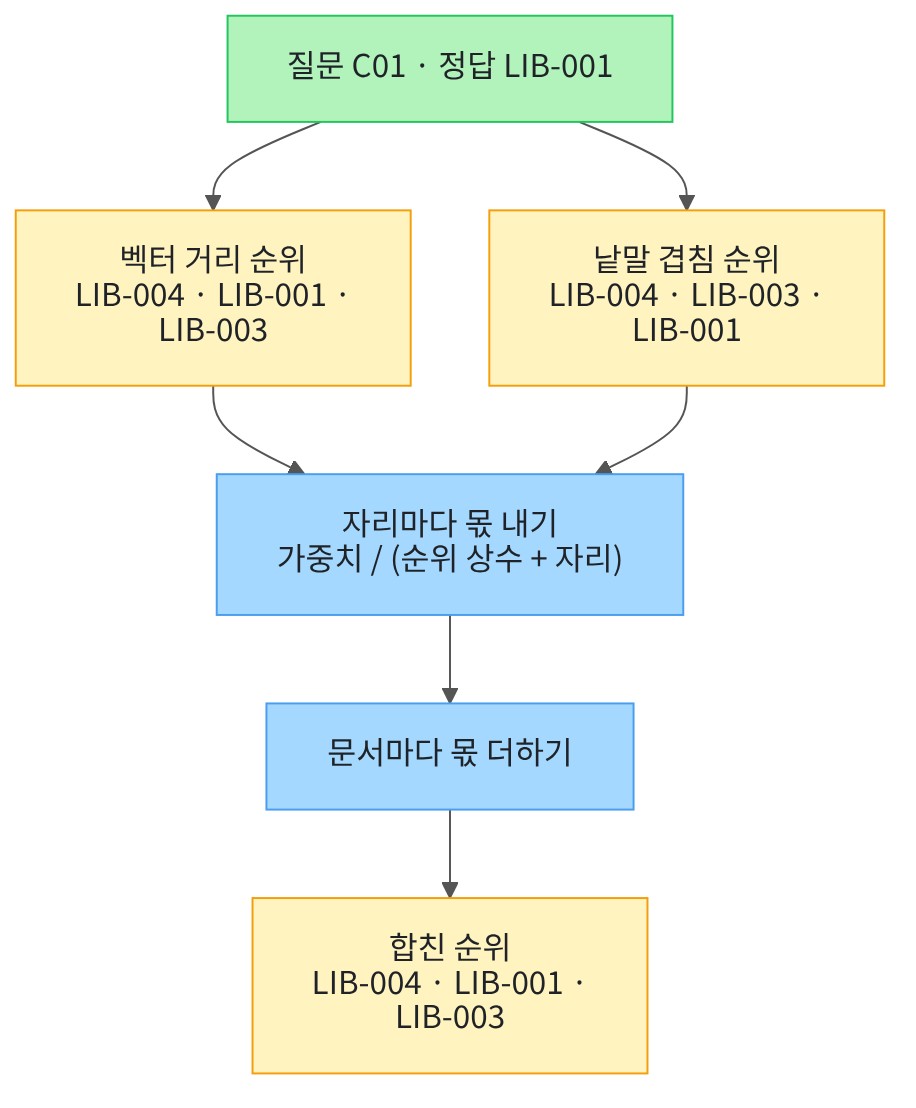

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 버전을 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `rank-bm25: 0.2.2`가 보입니다.
네 줄이 모두 보이면 다음 셀로 넘어갑니다.
05절과 같은 네 패키지입니다.

다음 셀은 이 절에서 쓸 이름 다섯 개를 불러옵니다.

In [2]:
# 자료 읽기·제곱근·임베딩·형태소 분석·낱말 점수에 쓸 이름을 불러옵니다
import json
import math

from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi

print("불러온 이름:", "json", "math", "Kiwi", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json math Kiwi OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 다섯 개가 붙은 한 줄입니다.
이름 `OpenAIEmbeddings`는 글을 벡터로 바꾸는 도구입니다.
이름 `Kiwi`와 `BM25Okapi`는 낱말 겹침 쪽에서 쓰는 두 도구입니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~05절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 01~05절이 쓴 문서 파일과 질문 파일을 그대로 읽습니다.

In [5]:
# 01~05절과 같은 문서 파일과 질문 파일을 불러옵니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/core-documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/core-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — `문서 수: 12`와 `질문 수: 8`이 보입니다.
01~05절과 같은 교육용 자료입니다.
같은 자료를 써야 05절에서 만든 두 순위를 그대로 합칠 수 있습니다.

## 2. 이 절에서 쓸 값 정하기

05절에서 쓴 값 여섯 개를 그대로 다시 정합니다.
이름 `top_all`은 자리를 셀 때 재는 문서 수입니다.
이름 `method_names`에 담을 방법이 05절 둘에서 셋으로 늘었습니다.

In [6]:
# 05절에서 쓴 값을 그대로 다시 정하고 견줄 방법 이름을 셋으로 늘립니다
similarity_top = 1
top_three = 3
top_all = 12
cutoff_values = [1, 2, 3]
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
method_names = ["벡터 거리", "낱말 겹침", "순위 합치기"]
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("나란히 볼 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)
print("자르는 자리 세 가지:", cutoff_values)
print("남길 품사 표시:", keep_tags)
print("견줄 방법 세 가지:", method_names)

코사인 유사도의 가장 큰 값: 1
나란히 볼 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12
자르는 자리 세 가지: [1, 2, 3]
남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
견줄 방법 세 가지: ['벡터 거리', '낱말 겹침', '순위 합치기']


**결과 읽기** — `자리를 셀 때 재는 문서 수: 12`가 보입니다.
출력 줄 `자르는 자리 세 가지: [1, 2, 3]`은 01~05절과 같은 값입니다.
줄 `견줄 방법 세 가지: ['벡터 거리', '낱말 겹침', '순위 합치기']`의 세 이름으로 기록을 나눕니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

다음 셀은 자리 번호를 몫으로 바꾸는 식에 쓸 값을 정합니다.
앞자리일수록 큰 몫을 주려고 자리 번호를 나누는 수에 넣습니다.
식은 `가중치 / (순위 상수 + 자리)`입니다.

In [7]:
# 자리 번호를 몫으로 바꾸는 식에 쓸 값을 정하고 앞자리 세 곳의 몫을 봅니다
rank_constant = 60
base_weight = 1.0
raised_weight = 1.5
equal_weights = [base_weight, base_weight]
sparse_up_weights = [base_weight, raised_weight]
print("순위 상수:", rank_constant)
print("같은 가중치:", equal_weights)
print("낱말 겹침 쪽만 올린 가중치:", sparse_up_weights)
print("자리 | 기본 가중치가 주는 몫")
for position in range(top_three):
    share = base_weight / (rank_constant + position + 1)
    print(position + 1, "|", round(share, 4))

순위 상수: 60
같은 가중치: [1.0, 1.0]
낱말 겹침 쪽만 올린 가중치: [1.0, 1.5]
자리 | 기본 가중치가 주는 몫
1 | 0.0164
2 | 0.0161
3 | 0.0159


**결과 읽기** — 라벨 줄 아래 세 줄이 자리 1·2·3의 몫입니다.
자리 1은 `1 | 0.0164`이고 자리 3은 `3 | 0.0159`입니다.
자리가 하나 뒤로 갈 때마다 몫이 조금씩 줄어듭니다.
줄 `순위 상수: 60`의 60은 앞자리 사이의 차이를 줄이려고 더하는 수입니다.
출력 줄 `낱말 겹침 쪽만 올린 가중치: [1.0, 1.5]`는 7절에서 쓸 값입니다.

## 3. 두 방법이 볼 재료 만들기

두 방법은 같은 글에서 서로 다른 재료를 만듭니다.
먼저 문서 12개의 제목과 본문을 이어 붙여 글 열두 개로 만듭니다.

In [8]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID 목록도 만듭니다(01~05절과 같은 모양)
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
print("이어 붙인 글 수:", len(doc_texts))
print("첫 문서 글:", doc_texts[0])
print("문서 ID 목록:")
print(doc_ids)

이어 붙인 글 수: 12
첫 문서 글: 도서 대출 기간 일반 도서는 14일 동안 대출할 수 있습니다. 예약자가 없으면 한 번 연장할 수 있습니다.
문서 ID 목록:
['LIB-001', 'LIB-002', 'LIB-003', 'LIB-004', 'FAC-001', 'FAC-002', 'FAC-003', 'FAC-004', 'ACC-001', 'ACC-002', 'ACC-003', 'ACC-004']


**결과 읽기** — `이어 붙인 글 수: 12`가 보입니다.
출력 줄 `첫 문서 글:` 뒤에는 제목 `도서 대출 기간`과 본문이 이어져 있습니다.
라벨 줄 `문서 ID 목록:` 아래 줄에 `LIB-001`부터 열두 개가 있습니다.

다음 셀은 벡터 거리 쪽 재료를 만듭니다.
01~03절·05절과 같은 모델과 같은 숫자 개수를 씁니다.

In [9]:
# 01~03절·05절과 같은 모델로 문서 12개와 질문 8개를 벡터로 바꿉니다(임베딩 요청 9번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
query_vectors = []
for query in queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12
질문 벡터 수: 8


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 벡터 수: 12`가 보입니다.
출력 줄 `질문 벡터 수: 8`까지 나오면 임베딩 요청 아홉 번이 끝났습니다.
이 노트북의 출력은 2026-09-18에 이 모델로 실행한 결과입니다.

다음 셀은 낱말 겹침 쪽 재료를 만들 함수를 준비합니다.
04·05절과 같은 함수이고 남길 품사 표시에 든 형태소만 남깁니다.

In [10]:
# 04·05절과 같은 형태소 분석기를 준비하고 남길 품사 표시에 든 형태소만 고르는 함수를 정의합니다
kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

**결과 읽기** — 정의 셀이라 출력이 없습니다.
분석기를 만드는 줄 `kiwi = Kiwi()`는 1초 안팎 걸립니다.

다음 셀은 문서 12개의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [11]:
# 문서 12개의 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04·05절과 같은 코드)
kiwi_corpus = []
for text in doc_texts:
    kiwi_corpus.append(kiwi_terms(text))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 수:", bm25_model.corpus_size)
print("문서 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 12
BM25 모델이 본 문서 수: 12
문서 하나의 평균 검색 낱말 수: 15.33


**결과 읽기** — `검색 낱말 목록 수: 12`와 `BM25 모델이 본 문서 수: 12`가 보입니다.
출력 줄 `문서 하나의 평균 검색 낱말 수: 15.33`은 04·05절과 같은 값입니다.

## 4. 두 방법의 순위 목록 만들기

01절에서 만든 함수 네 개를 같은 코드로 다시 정의합니다.
점곱과 길이로 코사인 유사도를 내고 그 값을 거리로 바꿉니다.

In [12]:
# 두 벡터의 점곱(같은 자리 숫자끼리 곱해 모두 더한 값)을 반환하는 함수를 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 벡터의 길이를 내는 함수입니다.

In [13]:
# 벡터의 길이(자기 자신과의 점곱에 제곱근을 씌운 값)를 반환하는 함수를 정의합니다
def vector_length(vector):
    # 자기 자신과의 점곱은 숫자마다 제곱해 더한 값입니다
    squared_sum = dot_product(vector, vector)
    # math.sqrt(수)는 제곱근을 반환합니다
    return math.sqrt(squared_sum)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 두 벡터의 코사인 유사도를 내는 함수입니다.

In [14]:
# 두 벡터의 코사인 유사도(점곱을 두 길이의 곱으로 나눈 값)를 반환하는 함수를 정의합니다
def cosine_similarity(first, second):
    dot = dot_product(first, second)
    # 두 길이를 곱한 값으로 나누면 화살표 길이와 관계없이 방향만 비교합니다
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 유사도를 거리로 바꾸는 함수입니다.
유사도는 클수록 가깝고 거리는 작을수록 가깝습니다.

In [15]:
# 코사인 유사도를 코사인 거리로 바꾸는 함수를 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    # 가장 큰 값 1에서 빼면 값이 작을수록 가까운 자가 됩니다
    return similarity_top - similarity

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 질문 하나를 문서 12개 모두와 재어 순위를 만듭니다.
05절과 같은 코드이고 값 칸 이름은 `거리`입니다.

In [16]:
# 질문 벡터 하나를 문서 12개 모두와 재어 거리가 작은 순서로 순위 목록을 만듭니다(05절과 같은 코드)
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(doc_ids)):
        distance = cosine_distance(question_vector, doc_vectors[i])
        pairs.append((distance, doc_ids[i]))
    hit_list = []
    # sorted(목록)는 튜플의 첫 값인 거리를 작은 값부터 정렬합니다
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `top_count`로 앞에서 몇 개를 남길지 정합니다.

다음 셀은 낱말 겹침 쪽 순위 함수입니다. 05절과 같은 코드입니다.

In [17]:
# 질문 하나를 낱말 겹침으로 재어 점수가 큰 순서로 순위 목록을 만듭니다(05절과 같은 코드)
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(doc_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], doc_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"doc_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
값 칸 이름은 `점수`입니다. 앞 함수의 `거리`와 뜻이 반대라 이름을 갈랐습니다.

다음 셀은 순위 목록에서 문서 ID만 차례로 모으는 함수입니다.
합치는 함수에 넣을 재료가 바로 이 문서 ID 목록입니다.

In [18]:
# 순위 목록에서 문서 ID를 차례로 모으고 처음 나온 것만 남깁니다(Ch 11 01절과 같은 코드)
def unique_doc_ids(hit_list):
    doc_ids = []
    for hit in hit_list:
        if hit["doc_id"] not in doc_ids:
            doc_ids.append(hit["doc_id"])
    return doc_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 함수가 보는 키는 `doc_id` 하나여서 두 방법의 순위 목록에 모두 씁니다.

다음 셀은 목록에서 찾는 문서 ID가 몇 번째 자리인지 세는 함수입니다.
이 코드는 Ch 11 01절에서 정답 문서의 자리를 셀 때 만든 것과 같습니다.
이 절에서는 합친 순위 앞자리 문서의 자리를 찾을 때도 씁니다.

In [19]:
# 문서 ID 목록에서 찾는 ID가 몇 번째 자리인지 셉니다(Ch 11 01절과 같은 코드)
def find_gold_rank(doc_ids, gold_doc_ids):
    gold_rank = 0
    for position in range(len(doc_ids)):
        if doc_ids[position] in gold_doc_ids:
            gold_rank = position + 1
            break
    return gold_rank

**결과 읽기** — 정의 셀이라 출력이 없습니다.
찾는 ID가 목록에 없으면 0이 나옵니다.

다음 셀은 질문 여덟 개마다 두 방법의 순위 목록을 미리 만듭니다.
문서 12개를 끝까지 재므로 목록 하나에 문서 ID가 열두 개 들어갑니다.

In [20]:
# 질문 여덟 개마다 두 방법의 순위 목록을 문서 ID 차례로 미리 만들어 둡니다
distance_id_lists = []
score_id_lists = []
for query_index in range(len(queries)):
    distance_hits = rank_by_distance(query_vectors[query_index], top_all)
    score_hits = rank_by_bm25(queries[query_index]["question"], top_all)
    distance_id_lists.append(unique_doc_ids(distance_hits))
    score_id_lists.append(unique_doc_ids(score_hits))
print("만든 순위 목록 쌍 수:", len(distance_id_lists))
print("목록 하나의 문서 수:", len(distance_id_lists[0]))
print("첫 질문의 벡터 거리 순위 앞 세 개:", distance_id_lists[0][:top_three])
print("첫 질문의 낱말 겹침 순위 앞 세 개:", score_id_lists[0][:top_three])

만든 순위 목록 쌍 수: 8
목록 하나의 문서 수: 12
첫 질문의 벡터 거리 순위 앞 세 개: ['LIB-004', 'LIB-001', 'LIB-003']
첫 질문의 낱말 겹침 순위 앞 세 개: ['LIB-004', 'LIB-003', 'LIB-001']


**결과 읽기** — `만든 순위 목록 쌍 수: 8`과 `목록 하나의 문서 수: 12`가 보입니다.
줄 `첫 질문의 벡터 거리 순위 앞 세 개: ['LIB-004', 'LIB-001', 'LIB-003']`은 05절 실행 1과 같습니다.
낱말 겹침 쪽은 `['LIB-004', 'LIB-003', 'LIB-001']`로 둘째와 셋째가 서로 바뀌어 있습니다.

## 5. 자리 번호로 합치는 함수 만들기

두 목록에는 값이 아니라 문서 ID만 들어 있습니다.
합치는 함수는 그 목록에서 자리 번호만 보고 몫을 냅니다.
그래서 거리와 점수의 크기가 달라도 두 결과를 함께 쓸 수 있습니다.

In [21]:
# 순위 목록 여러 개를 받아 문서마다 자리 몫을 더한 합친 점수를 냅니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            doc_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[doc_id] = scores.get(doc_id, 0.0) + share
    return scores

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `ranking_list`에 순위 목록 두 개를 담아 넘깁니다.
줄 `scores.get(doc_id, 0.0) + share`는 아직 없는 문서 ID의 몫을 0에서 시작합니다.

다음 셀은 합친 점수가 큰 순서로 문서 ID 목록을 만듭니다.
점수는 클수록 앞이라 04·05절처럼 점수에 음수를 붙여 정렬합니다.

In [22]:
# 합친 점수가 큰 순서로 문서 ID 목록을 만듭니다(04·05절과 같은 음수 붙이기)
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for doc_id in scores:
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[doc_id], doc_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

**결과 읽기** — 정의 셀이라 출력이 없습니다.
합친 점수가 같은 문서가 있으면 문서 ID 차례가 자리를 정합니다.

## 6. 실행 1 — 두 순위를 같은 가중치로 합치기

첫 질문의 두 순위 목록을 같은 가중치로 합칩니다.
실행 전에 예상해 봅니다.
두 방법이 모두 자리 1에 둔 `LIB-004`가 합친 순위에서도 1위일 것입니다.

In [23]:
# 실행 1: 첫 질문의 두 순위 목록을 같은 가중치로 합칩니다
first_query = queries[0]
first_ranking_list = [distance_id_lists[0], score_id_lists[0]]
first_scores = fuse_scores(first_ranking_list, equal_weights)
first_fused_ids = fuse_rank(first_ranking_list, equal_weights)
print("고른 질문:", first_query["qid"], "|", first_query["question"])
print("그 질문의 정답 문서 ID:", first_query["gold_doc_id"])
print("순위 | 문서 ID | 벡터 거리 자리 | 낱말 겹침 자리 | 합친 점수")
for position in range(top_three):
    doc_id = first_fused_ids[position]
    distance_place = find_gold_rank(distance_id_lists[0], [doc_id])
    score_place = find_gold_rank(score_id_lists[0], [doc_id])
    print(position + 1, "|", doc_id, "|", distance_place, "|", score_place, "|", round(first_scores[doc_id], 5))

고른 질문: C01 | 책을 빌릴 수 있는 기간은 며칠인가요?
그 질문의 정답 문서 ID: LIB-001
순위 | 문서 ID | 벡터 거리 자리 | 낱말 겹침 자리 | 합친 점수
1 | LIB-004 | 1 | 1 | 0.03279
2 | LIB-001 | 2 | 3 | 0.032
3 | LIB-003 | 3 | 2 | 0.032


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1 | LIB-004 | 1 | 1 | 0.03279`입니다.
그 문서는 두 방법에서 모두 자리 1이라 가장 큰 몫을 두 번 받았습니다.
둘째 줄 `2 | LIB-001 | 2 | 3 | 0.032`와 셋째 줄 `3 | LIB-003 | 3 | 2 | 0.032`는 합친 점수가 같습니다.
두 문서의 자리 번호가 2와 3으로 서로 바뀐 짝이라 몫의 합이 같아졌습니다.

정답 문서 `LIB-001`의 자리는 2입니다.
합친 점수가 같을 때 자리를 정하는 것은 이 코드의 정렬 규칙입니다.
04절에서 본 대로 점수가 같은 자리는 결과로 읽지 않습니다.

## 7. 값 바꿔 보기 — 가중치 하나만 올리기

바꿀 값은 낱말 겹침 쪽 가중치 하나입니다.
문서와 질문, 순위 상수, 두 순위 목록은 그대로 둡니다.
실행 전에 예상해 봅니다. 낱말 겹침이 앞에 둔 문서가 위로 올라올 것입니다.

In [24]:
# 값 바꿔 보기: 같은 두 순위 목록에서 낱말 겹침 쪽 가중치만 올립니다
second_scores = fuse_scores(first_ranking_list, sparse_up_weights)
second_fused_ids = fuse_rank(first_ranking_list, sparse_up_weights)
print("쓴 가중치:", sparse_up_weights)
print("순위 | 문서 ID | 벡터 거리 자리 | 낱말 겹침 자리 | 합친 점수")
for position in range(top_three):
    doc_id = second_fused_ids[position]
    distance_place = find_gold_rank(distance_id_lists[0], [doc_id])
    score_place = find_gold_rank(score_id_lists[0], [doc_id])
    print(position + 1, "|", doc_id, "|", distance_place, "|", score_place, "|", round(second_scores[doc_id], 5))

쓴 가중치: [1.0, 1.5]
순위 | 문서 ID | 벡터 거리 자리 | 낱말 겹침 자리 | 합친 점수
1 | LIB-004 | 1 | 1 | 0.04098
2 | LIB-003 | 3 | 2 | 0.04007
3 | LIB-001 | 2 | 3 | 0.03994


**결과 읽기** — 출력 줄 `쓴 가중치: [1.0, 1.5]` 아래 표에서 둘째와 셋째가 서로 바뀌었습니다.
둘째 줄은 `2 | LIB-003 | 3 | 2 | 0.04007`이고 셋째 줄은 `3 | LIB-001 | 2 | 3 | 0.03994`입니다.
정답 문서 `LIB-001`의 자리가 2에서 3으로 내려갔습니다.

낱말 겹침 쪽 몫이 한 배 반이 되면서 같았던 두 점수가 갈렸습니다.
낱말 겹침 순위에서 앞자리였던 `LIB-003`이 위로 올라갔습니다.
가중치를 올려도 BM25 점수 자체는 바뀌지 않습니다.
합친 점수에서 낱말 겹침 순위가 차지하는 몫만 커집니다.

## 8. 질문 여덟 개를 잴 함수 준비

질문 하나로는 세 방법의 차이를 말할 수 없습니다.
Ch 11과 01~05절에서 쓴 지표 함수 두 개를 그대로 이어 씁니다.

In [25]:
# 문서 ID 목록을 자르는 자리에서 자르고 정답 문서가 들어온 비율을 냅니다(Ch 11 02절과 같은 코드)
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
자르는 자리까지 자른 목록에 정답 문서가 있으면 1.0이 나옵니다.

다음 셀은 질문마다 낸 점수를 같은 무게로 평균하는 함수입니다.

In [26]:
# 질문마다 낸 점수를 같은 무게로 평균해 소수 셋째 자리까지 남깁니다(Ch 11 02절과 같은 코드)
def mean_score(score_list):
    total = 0
    for score in score_list:
        total = total + score
    return round(total / len(score_list), 3)

**결과 읽기** — 정의 셀이라 출력이 없습니다.

다음 셀은 문서 ID 목록 하나를 받아 기록 한 줄을 만듭니다.
값 칸을 두지 않아 세 방법을 한 표에 담을 수 있습니다.

In [27]:
# 문서 ID 목록 하나를 받아 정답 자리와 자르는 자리별 재현율을 기록 한 줄로 만듭니다
def score_one(query_index, method_name, found_ids):
    query = queries[query_index]
    gold_doc_ids = [query["gold_doc_id"]]
    row = {"방법": method_name, "질문": query["qid"], "갈래": query["kind"]}
    row["정답 자리"] = find_gold_rank(found_ids, gold_doc_ids)
    for cutoff in cutoff_values:
        row["자리 " + str(cutoff)] = recall_at(found_ids, gold_doc_ids, cutoff)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `found_ids`를 밖에서 받으므로 이 함수는 어느 방법인지 보지 않습니다.

## 9. 세 방법의 재현율 견주기

질문 여덟 개를 세 방법으로 모두 잽니다.
순위 목록을 미리 만들어 두었으므로 요청은 더 보내지 않습니다.

In [28]:
# 질문 여덟 개를 세 방법으로 모두 재어 기록 줄을 담습니다(임베딩 요청은 더 보내지 않습니다)
score_rows = []
for method_name in method_names:
    for query_index in range(len(queries)):
        # 세 방법이 갈리는 곳은 이 조건 세 갈래뿐입니다
        if method_name == method_names[0]:
            found_ids = distance_id_lists[query_index]
        elif method_name == method_names[1]:
            found_ids = score_id_lists[query_index]
        else:
            ranking_list = [distance_id_lists[query_index], score_id_lists[query_index]]
            found_ids = fuse_rank(ranking_list, equal_weights)
        score_rows.append(score_one(query_index, method_name, found_ids))
print("담은 기록 줄 수:", len(score_rows))

담은 기록 줄 수: 24


**결과 읽기** — `담은 기록 줄 수: 24`가 보입니다.
질문 여덟 개에 방법 세 가지를 곱한 수입니다.

다음 셀은 담은 줄을 표로 출력합니다.

In [29]:
# 방법·질문·갈래·정답 자리·자리 1·자리 3을 라벨 줄 아래에 차례로 출력합니다
print("방법 | 질문 | 갈래 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율")
for row in score_rows:
    print(row["방법"], "|", row["질문"], "|", row["갈래"], "|", row["정답 자리"], "|", row["자리 1"], "|", row["자리 3"])

방법 | 질문 | 갈래 | 정답 자리 | 자리 1 재현율 | 자리 3 재현율
벡터 거리 | C01 | semantic | 2 | 0.0 | 1.0
벡터 거리 | C02 | semantic | 7 | 0.0 | 0.0
벡터 거리 | C03 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C04 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C05 | semantic | 1 | 1.0 | 1.0
벡터 거리 | C06 | semantic | 1 | 1.0 | 1.0
벡터 거리 | C07 | keyword | 1 | 1.0 | 1.0
벡터 거리 | C08 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C01 | semantic | 3 | 0.0 | 1.0
낱말 겹침 | C02 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C03 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C04 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C05 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C06 | semantic | 1 | 1.0 | 1.0
낱말 겹침 | C07 | keyword | 1 | 1.0 | 1.0
낱말 겹침 | C08 | semantic | 1 | 1.0 | 1.0
순위 합치기 | C01 | semantic | 2 | 0.0 | 1.0
순위 합치기 | C02 | semantic | 3 | 0.0 | 1.0
순위 합치기 | C03 | keyword | 1 | 1.0 | 1.0
순위 합치기 | C04 | keyword | 1 | 1.0 | 1.0
순위 합치기 | C05 | semantic | 1 | 1.0 | 1.0
순위 합치기 | C06 | semantic | 1 | 1.0 | 1.0
순위 합치기 | C07 | keyword | 1 | 1.0 | 1.0
순위 합치기 | C08 | semantic | 1 | 1.0 | 1.0


**결과 읽기** — 라벨 줄 아래 앞 여덟 줄이 벡터 거리이고 그다음 여덟 줄이 낱말 겹침입니다.
마지막 여덟 줄이 순위 합치기이고 그 가운데 `순위 합치기 | C02 | semantic | 3 | 0.0 | 1.0` 줄이 있습니다.
같은 질문에서 벡터 거리는 `벡터 거리 | C02 | semantic | 7 | 0.0 | 0.0`이고 낱말 겹침은 자리 1입니다.
합친 자리 3은 두 방법의 자리 7과 1 사이입니다.

앞 열여섯 줄은 05절 표와 같은 값입니다.
세 방법 모두 문서 12개를 끝까지 재어 자리가 1에서 12까지 나옵니다.

다음 셀은 자르는 자리마다 질문 평균 재현율을 견줍니다.

In [30]:
# 세 방법의 질문 평균 재현율을 자르는 자리마다 견줍니다
print("방법 | 자르는 자리 | 질문 평균 재현율")
for method_name in method_names:
    picked = []
    for row in score_rows:
        if row["방법"] == method_name:
            picked.append(row)
    for cutoff in cutoff_values:
        picked_scores = []
        for row in picked:
            picked_scores.append(row["자리 " + str(cutoff)])
        print(method_name, "|", cutoff, "|", mean_score(picked_scores))

방법 | 자르는 자리 | 질문 평균 재현율
벡터 거리 | 1 | 0.75
벡터 거리 | 2 | 0.875
벡터 거리 | 3 | 0.875
낱말 겹침 | 1 | 0.875
낱말 겹침 | 2 | 0.875
낱말 겹침 | 3 | 1.0
순위 합치기 | 1 | 0.75
순위 합치기 | 2 | 0.875
순위 합치기 | 3 | 1.0


**결과 읽기** — 라벨 줄 아래 아홉 줄이 나옵니다.
벡터 거리는 `벡터 거리 | 1 | 0.75`이고 낱말 겹침은 `낱말 겹침 | 1 | 0.875`입니다.
순위 합치기는 `순위 합치기 | 1 | 0.75`로 벡터 거리와 같습니다.
자리 3에서는 `순위 합치기 | 3 | 1.0`으로 낱말 겹침과 같습니다.
세 방법의 자리 2 값은 모두 `0.875`입니다.

합친 값이 두 방법보다 높은 자리는 세 자리 가운데 없었습니다.
합쳤다고 해서 좋아지지는 않았습니다.

다음 셀은 가중치만 올린 합친 순위의 정답 자리를 견줍니다.

In [31]:
# 가중치만 올린 합친 순위를 질문 여덟 개에서 다시 재어 정답 자리를 견줍니다
print("질문 | 같은 가중치 자리 | 낱말 겹침 1.5 자리")
for query_index in range(len(queries)):
    ranking_list = [distance_id_lists[query_index], score_id_lists[query_index]]
    equal_ids = fuse_rank(ranking_list, equal_weights)
    raised_ids = fuse_rank(ranking_list, sparse_up_weights)
    gold_doc_ids = [queries[query_index]["gold_doc_id"]]
    equal_place = find_gold_rank(equal_ids, gold_doc_ids)
    raised_place = find_gold_rank(raised_ids, gold_doc_ids)
    print(queries[query_index]["qid"], "|", equal_place, "|", raised_place)

질문 | 같은 가중치 자리 | 낱말 겹침 1.5 자리
C01 | 2 | 3
C02 | 3 | 3
C03 | 1 | 1
C04 | 1 | 1
C05 | 1 | 1
C06 | 1 | 1
C07 | 1 | 1
C08 | 1 | 1


**결과 읽기** — 라벨 줄 아래 여덟 줄 가운데 값이 다른 줄은 `C01 | 2 | 3` 하나입니다.
질문 `C02`는 `C02 | 3 | 3`으로 두 가중치에서 자리가 같습니다.
나머지 여섯 질문은 두 가중치 모두 자리 1입니다.
가중치를 올려 자리가 앞으로 온 질문은 이번 실행에 없었습니다.

## 정리

1. 자리 번호만 써서 두 순위를 하나로 합치는 함수를 만들었습니다.
2. 질문 `C01`에서 합친 순위의 정답 자리는 2였고 가중치를 올리니 3이 되었습니다.
3. 이번 실행에서 합친 값이 두 방법보다 높은 자리는 없었습니다.

07절에서는 후보 목록을 고정해 두고 질문과 후보 본문을 함께 읽어 순서를 다시 정합니다.
그 절부터 쓰는 문서와 질문 묶음이 바뀝니다.